# Week 05 · Example Problems — 예제 문제 풀이

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week05_model_free_prediction/04_example_problems.ipynb)

슬라이드의 **"Example Problem 1–5"** 와 **"Quick Check: True or False?"** 를 코드로 풀어, 손으로 계산한 답을 확인합니다.
각 문제는 **문제 → 풀이 코드 → 슬라이드 답과 비교 → 한 걸음 더(작은 실험)** 순서입니다.
먼저 슬라이드의 문제를 손으로 풀어 본 뒤 셀을 실행해 답을 맞춰 보세요.

손 계산과 똑같은 숫자를 보기 위해 `fractions.Fraction`으로 **정확한 분수 계산**을 합니다(부동소수점 반올림 없음).

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이번 노트북 전용
from fractions import Fraction as F


def fmt(x):
    """Print a Fraction as an integer, a short decimal, or a fraction."""
    x = F(x)
    if x.denominator == 1:
        return str(x.numerator)
    d = float(x)
    return f"{d:g}" if abs(d * 10000 - round(d * 10000)) < 1e-9 else f"{x} (≈{d:.4f})"

### 에피소드 표기

슬라이드와 같이 에피소드를 **상태, 보상, 상태, 보상, …** 으로 적습니다. 마지막 보상 직후 종료 상태(값 0)에 도착합니다.
예를 들어 `["A", 2, "B", -1, "A", 3]`은 $S_1 = A,\ R_2 = 2,\ S_2 = B,\ R_3 = -1,\ S_3 = A,\ R_4 = 3$, 그리고 종료입니다.

In [2]:
def parse(episode):
    """Split [S_1, R_2, S_2, R_3, ...] into the list of states and the list of rewards."""
    states = list(episode[0::2])
    rewards = [F(r) for r in episode[1::2]]
    assert len(states) == len(rewards), "every state must be followed by a reward"
    return states, rewards


def returns(rewards, gamma=F(1)):
    """G_t for every time-step, computed backwards: G_t = R_{t+1} + gamma * G_{t+1}."""
    G, out = F(0), []
    for r in reversed(rewards):
        G = r + gamma * G
        out.append(G)
    return out[::-1]


def arrow(s, r, s_next):
    return f"{s} -({'+' if r >= 0 else ''}{fmt(r)})-> {s_next if s_next else 'end'}"

## 1. Example Problem 1: First-Visit vs. Every-Visit MC

$\gamma = 1$, 두 에피소드:

$$\text{Episode 1: } A,\ +2,\ B,\ -1,\ A,\ +3 \qquad \text{Episode 2: } B,\ +4,\ A,\ +1$$

1. 모든 시점의 리턴 $G_t$, 2. first-visit MC 추정, 3. every-visit MC 추정,
4. 증분 평균 $\mu_k = \mu_{k-1} + \frac{1}{k}(x_k - \mu_{k-1})$ 으로 every-visit $V(A)$ 다시 계산.

In [3]:
EPISODES = [["A", 2, "B", -1, "A", 3],
            ["B", 4, "A", 1]]

for k, ep in enumerate(EPISODES, 1):
    states, rewards = parse(ep)
    Gs = returns(rewards)
    print(f"Episode {k}: " + ",  ".join(f"t={t} {s}: G={fmt(G)}" for t, (s, G) in enumerate(zip(states, Gs), 1)))


def mc_estimates(episodes, first_visit, gamma=F(1)):
    """Mean of the observed returns per state (first-visit or every-visit). Returns (V, samples)."""
    samples = {}
    for ep in episodes:
        states, rewards = parse(ep)
        seen = set()
        for s, G in zip(states, returns(rewards, gamma)):
            if first_visit and s in seen:
                continue
            seen.add(s)
            samples.setdefault(s, []).append(G)
    V = {s: sum(g) / len(g) for s, g in samples.items()}
    return V, samples


V_first, samp_first = mc_estimates(EPISODES, first_visit=True)
V_every, samp_every = mc_estimates(EPISODES, first_visit=False)
for name, V, samp in [("first-visit", V_first, samp_first), ("every-visit", V_every, samp_every)]:
    for s in "AB":
        print(f"{name:12s} V({s}) = mean{[fmt(g) for g in samp[s]]} = {fmt(V[s])}")

# incremental mean over the every-visit returns of A
mu = F(0)
for k, x in enumerate(samp_every["A"], 1):
    mu = mu + (x - mu) / k
    print(f"  mu_{k} = {fmt(mu)}")

Episode 1: t=1 A: G=4,  t=2 B: G=2,  t=3 A: G=3
Episode 2: t=1 B: G=5,  t=2 A: G=1
first-visit  V(A) = mean['4', '1'] = 2.5
first-visit  V(B) = mean['2', '5'] = 3.5
every-visit  V(A) = mean['4', '3', '1'] = 8/3 (≈2.6667)
every-visit  V(B) = mean['2', '5'] = 3.5
  mu_1 = 4
  mu_2 = 3.5
  mu_3 = 8/3 (≈2.6667)


### 슬라이드와 비교

In [4]:
slide = {"first A": 2.5, "first B": 3.5, "every A": 2.67, "every B": 3.5}
ours = {"first A": V_first["A"], "first B": V_first["B"], "every A": V_every["A"], "every B": V_every["B"]}
print(f"{'':10s} {'slide':>7s} {'computed':>10s}")
for key in slide:
    print(f"{key:10s} {slide[key]:7.2f} {float(ours[key]):10.4f}")
    assert abs(float(ours[key]) - slide[key]) < 0.005
assert mu == V_every["A"] == F(8, 3)
assert [returns(parse(ep)[1]) for ep in EPISODES] == [[4, 2, 3], [5, 1]]

             slide   computed
first A       2.50     2.5000
first B       3.50     3.5000
every A       2.67     2.6667
every B       3.50     3.5000


두 방법은 $B$에서는 같고(에피소드마다 한 번만 방문), 한 에피소드에서 두 번 나온 $A$에서만 다릅니다.
every-visit은 두 번째 방문의 리턴 $3$까지 평균에 넣습니다. 증분 평균은 리턴을 저장하지 않고도 같은 $8/3$을 줍니다.

### 한 걸음 더: 데이터가 많아지면?

두 방법 모두 방문이 늘면 $v_\pi$로 수렴합니다(슬라이드: "$V(s) \to v_\pi(s)$ as $N(s) \to \infty$").
위 두 에피소드가 나올 법한 작은 MRP를 하나 정해 확인해 봅니다:
$A$에서는 $B$(보상 $+2$) 또는 종료(보상 $+3$, $+1$)로, $B$에서는 $A$(보상 $-1$ 또는 $+4$)로 갑니다.

true values: {'A': np.float64(5.5), 'B': np.float64(7.0)}


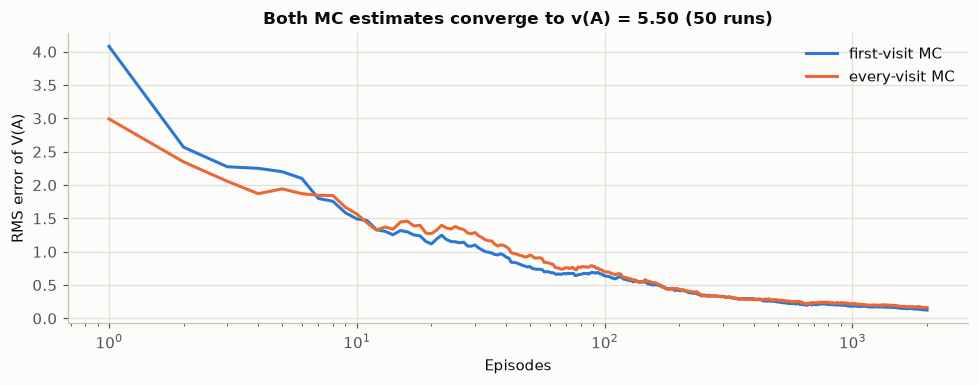

In [5]:
# A tiny MRP consistent with the two episodes (an assumption for this experiment, not part of the problem).
#   A -> B with reward +2 (prob 0.5),  A -> end with reward +3 (0.25) or +1 (0.25)
#   B -> A with reward -1 (prob 0.5) or +4 (prob 0.5)
P_A = [("B", 2, 0.5), (None, 3, 0.25), (None, 1, 0.25)]
P_B = [("A", -1, 0.5), ("A", 4, 0.5)]
# true values: v(A) = 0.5*(2 + v(B)) + 0.25*3 + 0.25*1,  v(B) = 0.5*(-1) + 0.5*4 + v(A)
M = np.array([[1.0, -0.5], [-1.0, 1.0]])
b = np.array([0.5 * 2 + 0.25 * 3 + 0.25 * 1, 0.5 * -1 + 0.5 * 4])
v_true = dict(zip("AB", np.linalg.solve(M, b)))
print("true values:", {s: round(v, 3) for s, v in v_true.items()})


def sample_episode(rng, start):
    ep, s = [], start
    while s is not None:
        table = P_A if s == "A" else P_B
        i = rng.choice(len(table), p=[p for _, _, p in table])
        nxt, r, _ = table[i]
        ep += [s, r]
        s = nxt
    return ep


def mc_curve(n_episodes, first_visit, seed):
    """Running MC estimate of V(A) after each episode (float arithmetic for speed)."""
    rng = np.random.default_rng(seed)
    total, count, curve = 0.0, 0, []
    for _ in range(n_episodes):
        ep = sample_episode(rng, start=rng.choice(["A", "B"]))
        states, rewards = ep[0::2], ep[1::2]
        G, Gs = 0.0, []
        for r in reversed(rewards):
            G = r + G
            Gs.append(G)
        Gs = Gs[::-1]
        seen = set()
        for s, g in zip(states, Gs):
            if s == "A" and not (first_visit and s in seen):
                total, count = total + g, count + 1
            seen.add(s)
        curve.append(total / count if count else np.nan)
    return np.array(curve)


n_ep, n_runs = 2000, 50
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (fv, label) in enumerate([(True, "first-visit MC"), (False, "every-visit MC")]):
    curves = np.array([mc_curve(n_ep, fv, seed) for seed in range(n_runs)])
    err = np.sqrt(np.nanmean((curves - v_true["A"]) ** 2, axis=0))
    ax.plot(np.arange(1, n_ep + 1), err, color=PALETTE[i], label=label)
ax.set_xscale("log")
ax.set_xlabel("Episodes")
ax.set_ylabel("RMS error of V(A)")
ax.set_title(f"Both MC estimates converge to v(A) = {v_true['A']:.2f} ({n_runs} runs)")
ax.legend()
plt.tight_layout()
plt.show()

두 곡선 모두 에피소드 수가 늘수록 0으로 내려갑니다. 처음 몇 에피소드에서는 every-visit의 오차가 더 작습니다(한 에피소드에서 표본을 더 많이 얻음).
그 뒤로는 비슷하거나 every-visit이 약간 큰데, 같은 에피소드 안의 표본끼리 서로 독립이 아니고 유한 표본에서는 약간 편향되기 때문입니다.
데이터가 충분히 많으면 둘의 차이는 사라집니다.

## 2. Example Problem 2: TD(0) by Hand

같은 두 에피소드를 순서대로 학습합니다. $V(A) = V(B) = 0$, 종료 상태 값 $0$, $\alpha = 0.5$, $\gamma = 1$.

1. TD(0)을 **매 스텝(online)** 적용하며 $\delta_t = R_{t+1} + \gamma V(S_{t+1}) - V(S_t)$ 와 새 값을 적기
2. 에피소드 1, 2가 끝난 뒤의 $V(A), V(B)$
3. constant-$\alpha$ MC(에피소드 끝에 적용)와 비교: 에피소드 1 뒤 $V(B)$가 왜 다른가?

In [6]:
def td0_online(episodes, alpha, gamma=F(1)):
    """Online TD(0). Returns the final V and a log of every step."""
    V = {"A": F(0), "B": F(0)}
    log = []
    for k, ep in enumerate(episodes, 1):
        states, rewards = parse(ep)
        for t, (s, r) in enumerate(zip(states, rewards)):
            s_next = states[t + 1] if t + 1 < len(states) else None
            v_next = V[s_next] if s_next else F(0)
            delta = r + gamma * v_next - V[s]
            V[s] += alpha * delta
            log.append((k, arrow(s, r, s_next), delta, s, V[s], dict(V)))
    return V, log


def mc_const_alpha(episodes, alpha, gamma=F(1)):
    """Constant-alpha every-visit MC, updates applied in time order at the end of each episode."""
    V = {"A": F(0), "B": F(0)}
    history = []
    for ep in episodes:
        states, rewards = parse(ep)
        for s, G in zip(states, returns(rewards, gamma)):
            V[s] += alpha * (G - V[s])
        history.append(dict(V))
    return V, history


ALPHA = F(1, 2)
V_td, td_log = td0_online(EPISODES, ALPHA)
print(f"{'ep':>2s}  {'step':16s} {'delta':>6s}   update")
for k, step, delta, s, v_new, _ in td_log:
    print(f"{k:>2d}  {step:16s} {fmt(delta):>6s}   V({s}) = {fmt(v_new)}")
after_ep1_td = td_log[2][5]
print("\nTD(0) after episode 1:", {s: fmt(v) for s, v in after_ep1_td.items()},
      "  after episode 2:", {s: fmt(v) for s, v in V_td.items()})

V_mc, mc_hist = mc_const_alpha(EPISODES, ALPHA)
print("MC     after episode 1:", {s: fmt(v) for s, v in mc_hist[0].items()},
      "  after episode 2:", {s: fmt(v) for s, v in mc_hist[1].items()})

ep  step              delta   update
 1  A -(+2)-> B           2   V(A) = 1
 1  B -(-1)-> A           0   V(B) = 0
 1  A -(+3)-> end         2   V(A) = 2
 2  B -(+4)-> A           6   V(B) = 3
 2  A -(+1)-> end        -1   V(A) = 1.5

TD(0) after episode 1: {'A': '2', 'B': '0'}   after episode 2: {'A': '1.5', 'B': '3'}
MC     after episode 1: {'A': '2.5', 'B': '1'}   after episode 2: {'A': '1.75', 'B': '3'}


### 슬라이드와 비교

In [7]:
assert [d for _, _, d, _, _, _ in td_log] == [2, 0, 2, 6, -1]          # TD errors on the slide
assert after_ep1_td == {"A": 2, "B": 0} and V_td == {"A": F(3, 2), "B": 3}
assert mc_hist[0] == {"A": F(5, 2), "B": 1} and mc_hist[1] == {"A": F(7, 4), "B": 3}
print("All TD errors and values match the slide: TD (A, B) = (2, 0) -> (1.5, 3);  MC (A, B) = (2.5, 1) -> (1.75, 3).")

All TD errors and values match the slide: TD (A, B) = (2, 0) -> (1.5, 3);  MC (A, B) = (2.5, 1) -> (1.75, 3).


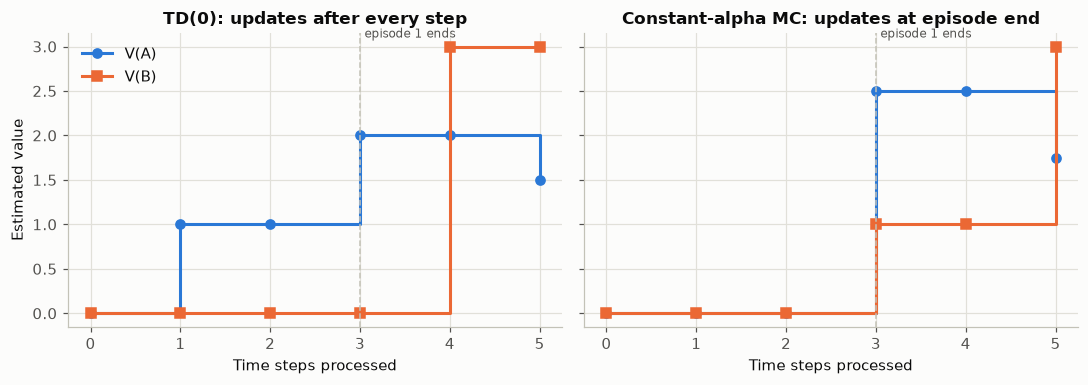

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
steps = np.arange(0, 6)
td_A = [0] + [float(h["A"]) for *_, h in td_log]
td_B = [0] + [float(h["B"]) for *_, h in td_log]
mc_A = [0, 0, 0, float(mc_hist[0]["A"]), float(mc_hist[0]["A"]), float(mc_hist[1]["A"])]
mc_B = [0, 0, 0, float(mc_hist[0]["B"]), float(mc_hist[0]["B"]), float(mc_hist[1]["B"])]
for ax, (a, b_, title) in zip(axes, [(td_A, td_B, "TD(0): updates after every step"),
                                    (mc_A, mc_B, "Constant-alpha MC: updates at episode end")]):
    ax.step(steps, a, where="post", color=PALETTE[0], marker="o", label="V(A)")
    ax.step(steps, b_, where="post", color=PALETTE[1], marker="s", label="V(B)")
    ax.axvline(3, color="#c3c2b7", lw=1, ls="--")
    ax.text(3.05, 3.1, "episode 1 ends", color="#52514e", fontsize=8)
    ax.set_xticks(steps)
    ax.set_xlabel("Time steps processed")
    ax.set_title(title)
axes[0].set_ylabel("Estimated value")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

TD(0)은 에피소드 도중에도 값이 바뀝니다. 두 번째 스텝($B \to A$)의 TD 오차가 $0$인 이유는 바로 앞 스텝에서
$V(A)$가 이미 $1$로 올라가 $-1 + 1 - 0 = 0$이 되었기 때문입니다.
반면 마지막 보상 $+3$은 그 시점의 $V(A)$에만 반영되고, $B$에는 **다음에 $B$를 방문할 때**(에피소드 2) 전달됩니다.
MC는 실제 리턴($B$의 리턴 $2$에 이미 $+3$이 포함)을 쓰므로 에피소드 1이 끝나자마자 $V(B) = 1$입니다.

## 3. Example Problem 3: Batch MC vs. Batch TD

세 상태 $A, B, C$, $\gamma = 1$, 네 에피소드를 수렴할 때까지 반복 학습:

$$A, 0, C, 1 \qquad B, 0, C, 0 \qquad B, 0, C, 0 \qquad C, 1$$

1. batch MC 해, 2. 최대우도 마르코프 모델과 batch TD(0) 해, 3. 7번의 방문에 대한 제곱 오차 합 비교.

In [9]:
BATCH = [["A", 0, "C", 1], ["B", 0, "C", 0], ["B", 0, "C", 0], ["C", 1]]
STATES3 = ["A", "B", "C"]

# 1. batch MC = mean of observed returns
V_mc3, samples3 = mc_estimates(BATCH, first_visit=False)

# 2. maximum-likelihood model: count transitions and average rewards
counts = {s: {} for s in STATES3}
reward_sum = {s: F(0) for s in STATES3}
visits = {s: 0 for s in STATES3}
for ep in BATCH:
    states, rewards = parse(ep)
    for t, (s, r) in enumerate(zip(states, rewards)):
        s_next = states[t + 1] if t + 1 < len(states) else "end"
        counts[s][s_next] = counts[s].get(s_next, 0) + 1
        reward_sum[s] += r
        visits[s] += 1
P_hat = {s: {s2: F(c, visits[s]) for s2, c in counts[s].items()} for s in STATES3}
R_hat = {s: reward_sum[s] / visits[s] for s in STATES3}
print("P_hat:", {s: {k: fmt(v) for k, v in d.items()} for s, d in P_hat.items()})
print("R_hat:", {s: fmt(v) for s, v in R_hat.items()})

# solve V = R_hat + P_hat V exactly (the model is acyclic here: A, B -> C -> end)
V_td3 = {"C": R_hat["C"]}
for s in ["A", "B"]:
    V_td3[s] = R_hat[s] + sum(p * V_td3.get(s2, F(0)) for s2, p in P_hat[s].items() if s2 != "end")


def sse(V):
    return sum((G - V[s]) ** 2 for s, gs in samples3.items() for G in gs)


print("\n        V(A)   V(B)   V(C)   sum of squared errors")
for name, V in [("MC", V_mc3), ("TD", V_td3)]:
    print(f"{name:5s} " + "  ".join(f"{fmt(V[s]):>5s}" for s in STATES3) + f"   {fmt(sse(V))}")

P_hat: {'A': {'C': '1'}, 'B': {'C': '1'}, 'C': {'end': '1'}}
R_hat: {'A': '0', 'B': '0', 'C': '0.5'}

        V(A)   V(B)   V(C)   sum of squared errors
MC        1      0    0.5   1
TD      0.5    0.5    0.5   1.75


### 슬라이드와 비교

In [10]:
assert V_mc3 == {"A": 1, "B": 0, "C": F(1, 2)}
assert V_td3 == {"A": F(1, 2), "B": F(1, 2), "C": F(1, 2)}
assert P_hat["A"] == {"C": 1} and P_hat["B"] == {"C": 1} and R_hat == {"A": 0, "B": 0, "C": F(1, 2)}
assert sse(V_mc3) == 1 and sse(V_td3) == F(7, 4)
print("Matches the slide: MC (1, 0, 0.5) with error 1;  TD (0.5, 0.5, 0.5) with error 1.75.")

Matches the slide: MC (1, 0, 0.5) with error 1;  TD (0.5, 0.5, 0.5) with error 1.75.


### 한 걸음 더 (1): 실제로 반복 학습하면 정말 그 해로 가는가?

슬라이드 "Batch MC and TD"처럼 네 에피소드를 계속 다시 보여 주며 작은 $\alpha$로 학습합니다(S&B의 batch updating:
한 번 훑는 동안의 증분을 모았다가 한꺼번에 적용).

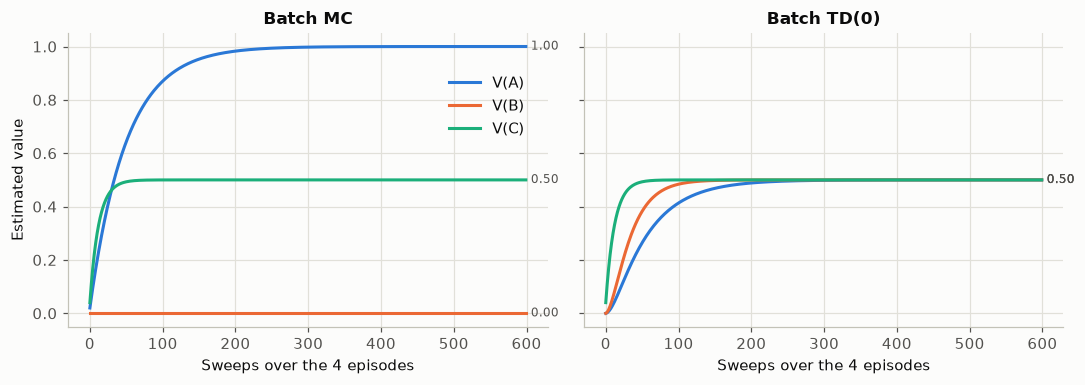

In [11]:
def batch_learn(method, alpha=0.02, sweeps=600):
    V = {s: 0.0 for s in STATES3}
    hist = []
    for _ in range(sweeps):
        inc = {s: 0.0 for s in STATES3}
        for ep in BATCH:
            states, rewards = ep[0::2], ep[1::2]
            Gs = [float(g) for g in returns([F(r) for r in rewards])]
            for t, (s, r) in enumerate(zip(states, rewards)):
                if method == "MC":
                    target = Gs[t]
                else:
                    v_next = V[states[t + 1]] if t + 1 < len(states) else 0.0
                    target = r + v_next
                inc[s] += alpha * (target - V[s])
        for s in STATES3:
            V[s] += inc[s]
        hist.append([V[s] for s in STATES3])
    return np.array(hist)


fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, method in zip(axes, ["MC", "TD"]):
    h = batch_learn(method)
    for i, s in enumerate(STATES3):
        ax.plot(h[:, i], color=PALETTE[i], label=f"V({s})")
        ax.text(len(h) * 1.01, h[-1, i], f"{h[-1, i]:.2f}", color="#52514e", fontsize=8, va="center")
    ax.set_title(f"Batch {method}(0)" if method == "TD" else "Batch MC")
    ax.set_xlabel("Sweeps over the 4 episodes")
axes[0].set_ylabel("Estimated value")
axes[0].legend(loc="center right", bbox_to_anchor=(0.98, 0.75))
plt.tight_layout()
plt.show()
hMC, hTD = batch_learn("MC"), batch_learn("TD")
assert np.allclose(hMC[-1], [1, 0, 0.5], atol=1e-3) and np.allclose(hTD[-1], [0.5, 0.5, 0.5], atol=1e-3)

### 한 걸음 더 (2): 어느 쪽을 믿어야 할까?

환경이 정말 마르코프라고 가정합니다: $A \to C$, $B \to C$(보상 0), $C$에서 보상 $1$을 받을 확률 $0.5$. 그러면 참값은
$v(A) = v(B) = v(C) = 0.5$입니다. 이 환경에서 **4개짜리(또는 20개짜리) 에피소드 묶음**을 새로 여러 번 뽑아, 묶음마다
batch MC 해와 batch TD 해를 구하고 참값과의 오차를 잽니다(시작 상태는 문제의 데이터처럼 $A$ 1/4, $B$ 1/2, $C$ 1/4).

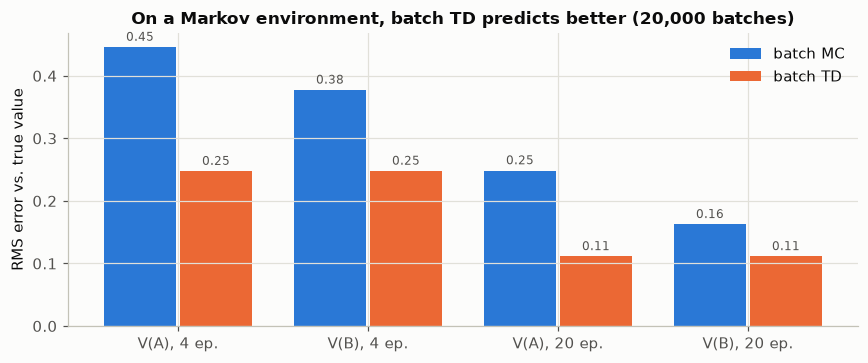

In [12]:
def batch_solutions(n_episodes, rng):
    starts = rng.choice(["A", "B", "C"], size=n_episodes, p=[0.25, 0.5, 0.25])
    rewards_C = rng.random(n_episodes) < 0.5                  # every episode ends with C's reward
    mc = {}
    for s in "AB":
        mask = starts == s
        mc[s] = rewards_C[mask].mean() if mask.any() else np.nan
    v_C = rewards_C.mean()                                    # C is visited in every episode
    td = {"A": v_C if (starts == "A").any() else np.nan, "B": v_C if (starts == "B").any() else np.nan}
    return mc, td


rng3 = np.random.default_rng(3)
rows = []
for n in [4, 20]:
    err = {("MC", s): [] for s in "AB"} | {("TD", s): [] for s in "AB"}
    for _ in range(20000):
        mc, td = batch_solutions(n, rng3)
        for s in "AB":
            if not np.isnan(mc[s]):
                err[("MC", s)].append((mc[s] - 0.5) ** 2)
                err[("TD", s)].append((td[s] - 0.5) ** 2)
    rows.append((n, {k: np.sqrt(np.mean(v)) for k, v in err.items()}))

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(4)
labels = ["V(A), 4 ep.", "V(B), 4 ep.", "V(A), 20 ep.", "V(B), 20 ep."]
mc_vals = [rows[0][1][("MC", "A")], rows[0][1][("MC", "B")], rows[1][1][("MC", "A")], rows[1][1][("MC", "B")]]
td_vals = [rows[0][1][("TD", "A")], rows[0][1][("TD", "B")], rows[1][1][("TD", "A")], rows[1][1][("TD", "B")]]
ax.bar(x - 0.2, mc_vals, width=0.38, color=PALETTE[0], label="batch MC")
ax.bar(x + 0.2, td_vals, width=0.38, color=PALETTE[1], label="batch TD")
for xi, (m, t) in enumerate(zip(mc_vals, td_vals)):
    ax.text(xi - 0.2, m + 0.01, f"{m:.2f}", ha="center", fontsize=8, color="#52514e")
    ax.text(xi + 0.2, t + 0.01, f"{t:.2f}", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, labels)
ax.set_ylabel("RMS error vs. true value")
ax.set_title("On a Markov environment, batch TD predicts better (20,000 batches)")
ax.legend()
plt.tight_layout()
plt.show()
assert all(td_vals[i] < mc_vals[i] for i in range(4))

MC는 $A$의 가치를 $A$에서 시작한 몇 안 되는 에피소드만으로 추정하지만, TD는 $A$가 늘 $C$로 간다는 구조를 이용해
$C$를 지나는 **모든** 에피소드의 정보를 씁니다. 그래서 관측된 리턴에 대한 오차는 MC가 더 작아도(문제 3번),
새 데이터에 대한 예측은 TD가 더 정확합니다. 환경이 마르코프가 아니라면(예: $A$에서 온 경우에만 $C$의 보상이 달라진다면)
이 장점은 사라지고 MC가 유리할 수 있습니다 — 슬라이드 "Advantages and Disadvantages of MC and TD (3)".

## 4. Example Problem 4: $n$-Step Returns and the $\lambda$-Return

$\gamma = 0.5$, 한 에피소드 $A,\ +1,\ B,\ 0,\ C,\ +2$ (3스텝 후 종료). 현재 추정값 $V(A) = 0.5,\ V(B) = 2,\ V(C) = 1$.

1. $G_1^{(1)}, G_1^{(2)}, G_1^{(3)}$, 2. $\lambda = 0.5$일 때 $G_1^{\lambda}$,
3. $G_1^{\lambda} - V(A) = \delta_1 + \gamma\lambda\delta_2 + (\gamma\lambda)^2\delta_3$ 확인, 4. $\lambda = 0$과 $\lambda = 1$일 때.

In [13]:
EP4 = ["A", 1, "B", 0, "C", 2]
V4 = {"A": F(1, 2), "B": F(2), "C": F(1)}
GAMMA4, LAM4 = F(1, 2), F(1, 2)


def n_step_return(states, rewards, V, t, n, gamma):
    """G_t^(n) with 0-based t; if the episode ends within n steps this is the MC return."""
    T = len(rewards)                       # number of steps in the episode
    G = F(0)
    for k in range(min(n, T - t)):
        G += gamma ** k * rewards[t + k]
    if t + n < T:                          # bootstrap from a non-terminal state
        G += gamma ** n * V[states[t + n]]
    return G


def lambda_return(states, rewards, V, t, lam, gamma):
    """Episodic lambda-return: weights (1-lam)lam^(n-1) for n < steps left, the rest (lam^(steps left - 1)) on G_t."""
    steps_left = len(rewards) - t
    G_lam = sum((1 - lam) * lam ** (n - 1) * n_step_return(states, rewards, V, t, n, gamma)
                for n in range(1, steps_left))
    return G_lam + lam ** (steps_left - 1) * n_step_return(states, rewards, V, t, steps_left, gamma)


states4, rewards4 = parse(EP4)
G_n = [n_step_return(states4, rewards4, V4, 0, n, GAMMA4) for n in (1, 2, 3)]
G_lam = lambda_return(states4, rewards4, V4, 0, LAM4, GAMMA4)
deltas4 = [rewards4[t] + GAMMA4 * (V4[states4[t + 1]] if t + 1 < 3 else 0) - V4[states4[t]] for t in range(3)]
telescoped = sum((GAMMA4 * LAM4) ** k * d for k, d in enumerate(deltas4))

print("n-step returns G_1^(1), G_1^(2), G_1^(3):", [fmt(g) for g in G_n])
print("lambda-return (lambda = 0.5):", fmt(G_lam))
print("TD errors:", [fmt(d) for d in deltas4], "->  sum (gamma*lambda)^k delta_k =", fmt(telescoped),
      "  G^lambda - V(A) =", fmt(G_lam - V4["A"]))
print("lambda = 0:", fmt(lambda_return(states4, rewards4, V4, 0, F(0), GAMMA4)),
      "  lambda = 1:", fmt(lambda_return(states4, rewards4, V4, 0, F(1), GAMMA4)))

n-step returns G_1^(1), G_1^(2), G_1^(3): ['2', '1.25', '1.5']
lambda-return (lambda = 0.5): 1.6875
TD errors: ['1.5', '-1.5', '1'] ->  sum (gamma*lambda)^k delta_k = 1.1875   G^lambda - V(A) = 1.1875
lambda = 0: 2   lambda = 1: 1.5


### 슬라이드와 비교

In [14]:
assert G_n == [2, F(5, 4), F(3, 2)]
assert G_lam == F(27, 16)                                   # 1.6875
assert deltas4 == [F(3, 2), F(-3, 2), 1] and telescoped == G_lam - V4["A"] == F(19, 16)
assert lambda_return(states4, rewards4, V4, 0, F(0), GAMMA4) == 2
assert lambda_return(states4, rewards4, V4, 0, F(1), GAMMA4) == F(3, 2)
print("Matches the slide: G^(n) = 2, 1.25, 1.5;  G^lambda = 1.6875;  telescoping 1.1875 = 1.6875 - 0.5.")

Matches the slide: G^(n) = 2, 1.25, 1.5;  G^lambda = 1.6875;  telescoping 1.1875 = 1.6875 - 0.5.


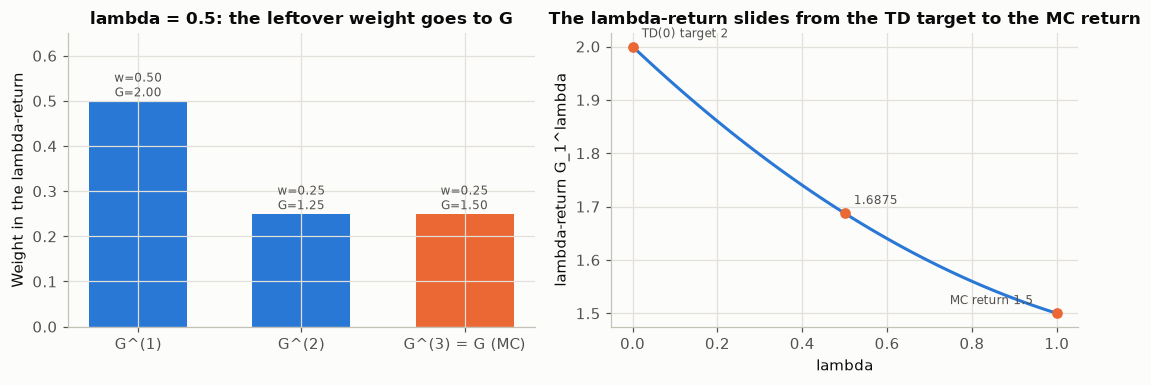

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
w = [float((1 - LAM4)), float((1 - LAM4) * LAM4), float(LAM4 ** 2)]
axes[0].bar([1, 2, 3], w, color=[PALETTE[0], PALETTE[0], PALETTE[1]], width=0.6)
for n, (wi, g) in enumerate(zip(w, G_n), 1):
    axes[0].text(n, wi + 0.01, f"w={wi:.2f}\nG={float(g):.2f}", ha="center", fontsize=8, color="#52514e")
axes[0].set_xticks([1, 2, 3], ["G^(1)", "G^(2)", "G^(3) = G (MC)"])
axes[0].set_ylabel("Weight in the lambda-return")
axes[0].set_ylim(0, 0.65)
axes[0].set_title("lambda = 0.5: the leftover weight goes to G")

lams = np.linspace(0, 1, 101)
curve = [float(lambda_return(states4, rewards4, V4, 0, F(l).limit_denominator(1000), GAMMA4)) for l in lams]
axes[1].plot(lams, curve, color=PALETTE[0])
axes[1].scatter([0, 0.5, 1], [2, 1.6875, 1.5], color=PALETTE[1], zorder=3)
for lx, ly, txt in [(0, 2, "TD(0) target 2"), (0.5, 1.6875, "1.6875"), (1, 1.5, "MC return 1.5")]:
    axes[1].annotate(txt, (lx, ly), textcoords="offset points", xytext=(6 if lx < 1 else -70, 6), fontsize=8, color="#52514e")
axes[1].set_xlabel("lambda")
axes[1].set_ylabel("lambda-return G_1^lambda")
axes[1].set_title("The lambda-return slides from the TD target to the MC return")
plt.tight_layout()
plt.show()

에피소드가 3스텝 뒤에 끝나므로 $n \ge 3$인 모든 $n$-step 리턴은 실제 리턴 $G_1 = 1.5$와 같고,
그 무한히 많은 가중치의 합 $\lambda^2$가 모두 $G_1$에 붙습니다(슬라이드 "TD($\lambda$) Weighting Function"의 마지막 막대).
$\lambda$를 0에서 1로 바꾸면 목표값이 TD(0) 목표에서 MC 리턴으로 매끄럽게 옮겨 갑니다.

## 5. Example Problem 5: Eligibility Traces

$\gamma = 1$, 한 에피소드 $A,\ 0,\ B,\ 0,\ A,\ +1$ ($A$를 두 번 방문). 모든 값 $0$에서 시작, $\lambda = 0.5$, $\alpha = 0.5$,
**offline** 갱신(에피소드 동안 갱신량을 모았다가 끝에 적용).

1. $t = 1, 2, 3$의 $\delta_t, E_t(A), E_t(B)$, 2. backward-view 총 갱신, 3. forward-view 총 갱신과 비교, 4. TD(0)이라면?

In [16]:
EP5 = ["A", 0, "B", 0, "A", 1]
states5, rewards5 = parse(EP5)


def offline_backward(lam, alpha=F(1, 2), gamma=F(1)):
    V = {"A": F(0), "B": F(0)}
    E = {"A": F(0), "B": F(0)}
    total = {"A": F(0), "B": F(0)}
    rows = []
    for t, (s, r) in enumerate(zip(states5, rewards5)):
        for k in E:
            E[k] *= gamma * lam                         # decay every trace
        E[s] += 1                                       # then bump the visited state
        v_next = V[states5[t + 1]] if t + 1 < len(states5) else F(0)
        delta = r + gamma * v_next - V[s]               # V stays fixed during the episode (offline)
        for k in E:
            total[k] += alpha * delta * E[k]
        rows.append((t + 1, s, delta, E["A"], E["B"]))
    return total, rows


def offline_forward(lam, alpha=F(1, 2), gamma=F(1)):
    V = {"A": F(0), "B": F(0)}
    total = {"A": F(0), "B": F(0)}
    G_lams = []
    for t, s in enumerate(states5):
        G = lambda_return(states5, rewards5, V, t, lam, gamma)
        G_lams.append(G)
        total[s] += alpha * (G - V[s])
    return total, G_lams


back, rows5 = offline_backward(F(1, 2))
fwd, G_lams5 = offline_forward(F(1, 2))
print(f"{'t':>2s} {'S_t':>4s} {'delta_t':>8s} {'E_t(A)':>8s} {'E_t(B)':>8s}")
for t, s, d, ea, eb in rows5:
    print(f"{t:>2d} {s:>4s} {fmt(d):>8s} {fmt(ea):>8s} {fmt(eb):>8s}")
print("\nbackward view: dV(A) =", fmt(back["A"]), "  dV(B) =", fmt(back["B"]))
print("forward view : lambda-returns", [fmt(g) for g in G_lams5], "-> dV(A) =", fmt(fwd["A"]), "  dV(B) =", fmt(fwd["B"]))
td0, _ = offline_backward(F(0))
print("TD(0)        : dV(A) =", fmt(td0["A"]), "  dV(B) =", fmt(td0["B"]))

 t  S_t  delta_t   E_t(A)   E_t(B)
 1    A        0        1        0
 2    B        0      0.5        1
 3    A        1     1.25      0.5

backward view: dV(A) = 0.625   dV(B) = 0.25
forward view : lambda-returns ['0.25', '0.5', '1'] -> dV(A) = 0.625   dV(B) = 0.25
TD(0)        : dV(A) = 0.5   dV(B) = 0


### 슬라이드와 비교

In [17]:
assert [(d, ea, eb) for _, _, d, ea, eb in rows5] == [(0, 1, 0), (0, F(1, 2), 1), (1, F(5, 4), F(1, 2))]
assert back == fwd == {"A": F(5, 8), "B": F(1, 4)}
assert G_lams5 == [F(1, 4), F(1, 2), 1]
assert td0 == {"A": F(1, 2), "B": 0}
print("Matches the slide: backward = forward = (0.625, 0.25);  TD(0) = (0.5, 0).")

Matches the slide: backward = forward = (0.625, 0.25);  TD(0) = (0.5, 0).


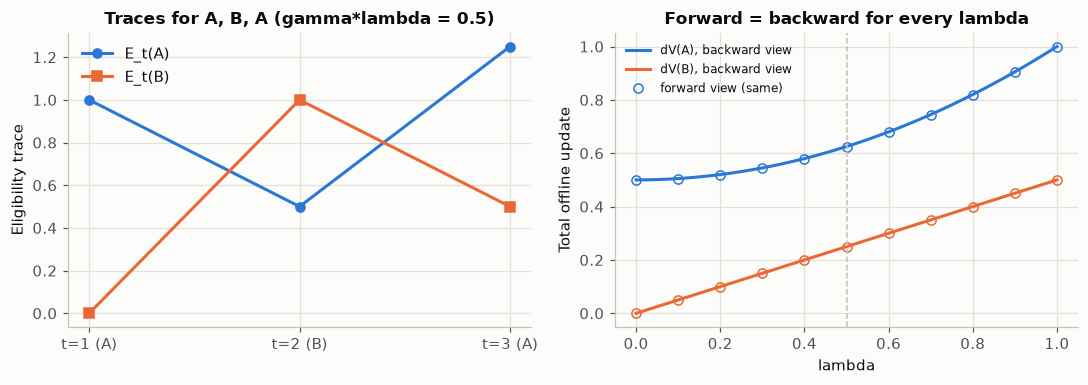

In [18]:
lams = np.linspace(0, 1, 41)
bA, bB, fA, fB = [], [], [], []
for l in lams:
    lf = F(l).limit_denominator(1000)
    b5, _ = offline_backward(lf)
    f5, _ = offline_forward(lf)
    bA.append(float(b5["A"])); bB.append(float(b5["B"]))
    fA.append(float(f5["A"])); fB.append(float(f5["B"]))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
t_axis = [1, 2, 3]
axes[0].plot(t_axis, [float(r[3]) for r in rows5], marker="o", color=PALETTE[0], label="E_t(A)")
axes[0].plot(t_axis, [float(r[4]) for r in rows5], marker="s", color=PALETTE[1], label="E_t(B)")
axes[0].set_xticks(t_axis, ["t=1 (A)", "t=2 (B)", "t=3 (A)"])
axes[0].set_ylabel("Eligibility trace")
axes[0].set_title("Traces for A, B, A (gamma*lambda = 0.5)")
axes[0].legend()

axes[1].plot(lams, bA, color=PALETTE[0], label="dV(A), backward view")
axes[1].plot(lams, bB, color=PALETTE[1], label="dV(B), backward view")
axes[1].plot(lams[::4], fA[::4], "o", color=PALETTE[0], mfc="none", label="forward view (same)")
axes[1].plot(lams[::4], fB[::4], "o", color=PALETTE[1], mfc="none")
axes[1].axvline(0.5, color="#c3c2b7", lw=1, ls="--")
axes[1].set_xlabel("lambda")
axes[1].set_ylabel("Total offline update")
axes[1].set_title("Forward = backward for every lambda")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
assert np.allclose(bA, fA) and np.allclose(bB, fB)

왼쪽: $A$의 trace는 두 번째 방문에서 $0.25 + 1 = 1.25$로 **쌓이고**(빈도), $B$의 trace는 마지막 방문 이후 반으로 줄어듭니다(최근성).
보상은 마지막 스텝에만 있으므로 갱신량은 그 시점의 trace에 비례합니다: $A$가 $B$보다 더 많은 credit을 받습니다.

오른쪽: $\lambda$를 0에서 1까지 바꿔도 backward view(선)와 forward view(원)의 총 갱신량이 정확히 같습니다
(슬라이드 "Forward and Backward View Are Equivalent (Offline)"). $\lambda = 0$이면 보상이 $B$까지 가지 못하고($\Delta V(B) = 0$),
$\lambda = 1$이면 every-visit MC와 같은 갱신이 됩니다($\Delta V(A) = 0.5\,(1 + 1) = 1$, $\Delta V(B) = 0.5$).

In [19]:
assert np.isclose(bA[-1], 1.0) and np.isclose(bB[-1], 0.5)       # lambda = 1 equals every-visit MC

## 6. Quick Check: True or False? — 정답과 근거

| # | 문장 | 정답 | 근거 (이 주차 노트북) |
|---|---|---|---|
| 1 | MC는 끝나지 않는(continuing) 과제에도 쓸 수 있다 | **False** | 리턴 $G_t$는 에피소드가 끝나야 계산됩니다 |
| 2 | TD 목표 $R_{t+1} + \gamma V(S_{t+1})$는 $v_\pi(S_t)$의 불편 추정량이다 | **False** | $V \neq v_\pi$이면 편향 — `02_td_prediction`의 bias/variance 절 |
| 3 | first-visit, every-visit MC 모두 방문이 늘면 $v_\pi(s)$로 수렴한다 | **True** | 위 1번 문제의 "한 걸음 더" 그림 |
| 4 | batch TD(0)은 최대우도 마르코프 모델의 가치로 수렴한다 | **True** | 위 3번 문제, `02_td_prediction`의 AB 예제 |
| 5 | $\lambda = 0$이면 backward-view TD($\lambda$)는 TD(0)과 같다 | **True** | $E_t(s) = \mathbf{1}(S_t = s)$ — 위 5번 문제의 $\lambda = 0$ |
| 6 | offline 갱신에서 TD(1)의 총 갱신은 every-visit MC와 같다 | **True** | 위 5번 문제의 $\lambda = 1$, `03_n_step_td_lambda`의 6절 |

## 직접 해보기

- **문제 2**에서 $\alpha = 1$로 바꿔 보세요. TD(0)은 매번 목표값으로 그대로 덮어쓰므로 Driving Home 예제와 같은 계산이 됩니다.
  두 에피소드를 여러 번 반복해서 보여 주면 TD와 MC의 값은 각각 어디로 갈까요? (`batch_learn`을 참고)
- **문제 3**의 데이터에 `["A", 0, "C", 0]`를 몇 개 추가해 보세요. MC의 $V(A)$와 TD의 $V(A)$는 각각 어떻게 바뀌나요?
- **문제 4**에서 $\gamma = 1$로 바꾸고 $G_1^{\lambda}$를 다시 계산해 보세요. $\gamma\lambda$가 커지면 뒤쪽 TD 오차의 비중이 어떻게 바뀌나요?
- **문제 5**에서 에피소드를 `["A", 0, "B", 0, "A", 0, "B", 1]`로 바꾸면 이번에는 $A$와 $B$ 중 누가 더 많은 credit을 받을까요?